# CAES Mini-Project: Variant 1b System Design and Simulation

Compressed Air Energy Storage (CAES) stores electricity during off-peak hours by compressing ambient air into a storage reservoir. During discharge, the compressed air is extracted, heated via a combustor, and expanded through a turbine to generate electricity.

## Variant 1b Description

**Variant 1b** models a single-stage, non-adiabatic CAES plant with a constant-pressure reservoir:

* **Charge:** Ambient air is compressed in a single-stage compressor directly to the storage pressure $P_{\text{max}}$. The heat of compression is removed via a water cooler and rejected to ambient (no thermal storage), bringing the air towards ambient temperature before storage.

* **Discharge:** Air leaves the store at a constant inlet pressure of 16 bar (quasi-steady expansion). A fuel combustor heats the air from near ambient conditions up to the turbine inlet temperature ($550^\circ\text{C}$) before it expands across a single turbine stage to ambient pressure.

## System Specifications & Given Parameters

| Category | Parameter | Symbol | Value | Unit / Description |
|---|---|---|---|---|
| **Fluid Properties** | Working fluid | — | Air | Real-gas properties via CoolProp (`"Air"`) |
| **Ambient Conditions** | Ambient temperature | $T_0$ | 15 (288.15) | °C (K) |
| | Ambient pressure | $P_0$ | 1.013 | bar (compressor inlet / turbine exhaust) |
| **Storage Conditions** | Storage / max pressure | $P_{\text{max}}$ | 16 | bar (held constant during operation) |
| | Reservoir thermal state | $T_{\text{res}}$ | 15 (288.15) | °C (assumed returns and remains at $T_0$) |
| **Operating Targets** | Discharge shaft power | $P_{\text{shaft}}$ | 1 | MW |
| | Discharge duration | $\Delta t_{\text{dis}}$ | 4 | h (delivers 4 MWh per cycle) |
| | Charge duration | $\Delta t_{\text{ch}}$ | 4 | h (governs charge mass flow rate) |
| **Component Efficiencies** | Compressor isentropic efficiency | $\eta_{\text{is,c}}$ | 0.85 | Single stage |
| | Turbine isentropic efficiency | $\eta_{\text{is,t}}$ | 0.88 | Single stage |
| | Mechanical / generator efficiency | $\eta_{\text{mech}}$ | 0.98 | Shaft transmission / generator conversion |
| **Thermal Parameters** | Cooler pinch | $\Delta T_{\text{pinch}}$ | 10 | K (air cooled towards $T_0 + 10\text{ K}$) |
| | Turbine inlet temperature | TIT | 550 (823.15) | °C (K), achieved via direct heat addition |
| | Reference fuel-to-electricity efficiency | $\eta_f$ | 0.40 | Metric weighting factor for fuel input |


# 1. Environment Setup & Thermodynamic Backends


In [ ]:
# --- Imports ---
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP
from caldis.fluids import CoolPropBackend
from caldis.solvers import simulate

# --- Fluid Property Backends (CoolProp) ---
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")
be_water = CoolPropBackend("Water")


Caldis version: 0.4.0


# 2. Plant Baseline Specifications & Operating Targets
Defines ambient boundary conditions, target power output, cycle durations, and nominal component efficiencies.


In [48]:
# ==============================================================================
# Global Ambient Boundary Conditions
# ==============================================================================
# [Thermodynamic State] Ambient temperature (15 °C)
T0 = 15.0 + 273.15           # [K]
# [Thermodynamic State] Ambient pressure (1.013 bar)
P0 = 1.013e5                 # [Pa]

# ==============================================================================
# Operational Cycle Targets
# ==============================================================================
# [Energy Rate / Power] Target turbine net shaft electrical power output
W_target = 1.0e6             # [W] (1 MW target)
# [Time Duration] Target discharge cycle duration (4 hours -> 4 MWh energy delivery)
t_discharge = 4.0 * 3600.0   # [s]
# [Time Duration] Target charge cycle duration (4 hours)
t_charge = 4.0 * 3600.0      # [s]

# ==============================================================================
# Cycle Operating Limits & Component Efficiencies
# ==============================================================================
# [Pressure Parameter] Nominal storage reservoir pressure (held isobaric)
Pmax = 16.0e5                # [Pa] 
# [Temperature Parameter] Turbine Inlet Temperature (TIT)
Ttit = 550.0 + 273.15        # [K] 
# [Temperature Parameter] Cooler approach pinch temperature difference
delta_T_pinch = 10.0         # [K] 

# [Efficiency Parameter] Single-stage compressor isentropic efficiency
Eta_ISC = 0.85               
# [Efficiency Parameter] Single-stage turbine isentropic efficiency
Eta_IST = 0.88               
# [Efficiency Parameter] Mechanical shaft / generator electrical efficiency
Eta_Mech = 0.98              
# [Efficiency Parameter] Reference fuel-to-electricity conversion efficiency
Eta_Fuel = 0.40               


# 3. Discharge Subsystem: Design, Sizing & Dynamic Simulation
The discharge cycle extracts compressed air from the isobaric reservoir, combusts methane fuel to reach $550^\circ\text{C}$ TIT, and expands the flue gas through the turbine down to ambient backpressure ($P_0$) to deliver 1 MW of electricity.


In [49]:
# ==============================================================================
# Discharge Thermodynamic States & Expansion Work
# ==============================================================================
# [Pressure Drop] Combustor relative pressure loss: dp_rel = 4%
dp_comb_rel = 0.04

# Turbine inlet pressure after combustor pressure drop
P_turb_in = Pmax * (1.0 - dp_comb_rel)                             # [Pa] 

# Enthalpy at turbine inlet (Ttit, P_turb_in)
h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in, "Air")        # [J/kg]

# Entropy at turbine inlet (Ttit, P_turb_in)
s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")        # [J/(kg·K)]

# Isentropic expansion enthalpy at ambient backpressure P0
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")       # [J/kg]

# Net shaft specific electrical work delivered per kg of air
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)             # [J/kg]

# ==============================================================================
# Discharge Mass Flow Rates & Sizing Mass
# ==============================================================================
# Air discharge mass flow rate required to deliver W_target (1 MW)
Mdot_discharge = W_target / w_sp                                   # [kg/s]

# [Mass Sizing] Total nominal air mass discharged over 4 hours
Mass_discharge_total = Mdot_discharge * t_discharge                # [kg]

# [Mass Flow Rate] Initial guess for fuel mass flow rate (methane LHV = 50 MJ/kg)
Mdot_fuel_guess = 0.286                                            # [kg/s]

# ==============================================================================
# Storage Reservoir Initial Sizing & Wall Thermal Properties (Stainless Steel 304)
# ==============================================================================
# Stored air enthalpy at discharge conditions (T0, Pmax)
h_tank_discharge = PropsSI("H", "T", T0, "P", Pmax, "Air")        # [J/kg]

# Stored air density at discharge conditions (T0, Pmax)
rho_tank_discharge = PropsSI("D", "T", T0, "P", Pmax, "Air")      # [kg/m³]

# Initial reservoir volume estimate based on storage density
V_tank_initial = Mass_discharge_total / rho_tank_discharge         # [m³]

# Stainless Steel 304 properties [Source: https://www.azom.com/properties.aspx?ArticleID=965]
Density_Steel_304 = 7955.0   # [kg/m³] Metal density
Cp_Tank = 500.0              # [J/(kg·K)] Metal specific heat capacity
k_steel = 16.0               # [W/(m·K)] Metal thermal conductivity

# Cylindrical vessel outer dimensions and wall thickness
Diameter_Tank_out = 8.0      # [m] Outer vessel diameter
Thickness_wall = 0.12        # [m] Shell wall thickness
r_out = Diameter_Tank_out / 2.0             # [m] Outer radius
r_in = r_out - Thickness_wall               # [m] Inner radius
r_mid = (r_out + r_in) / 2.0                # [m] Mid-wall radius

# Cross-sectional areas
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # [m²] Inner fluid cross-sectional area
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # [m²] Annular metal shell area

# Length and surface area based on initial volume
Length_Tank = V_tank_initial / Area_Tank_in_cs         # [m] Cylinder length
Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank   # [m²] Internal convective surface area
Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank   # [m³] Metal shell volume
Mass_Tank = Density_Steel_304 * Volume_Tank_Shell      # [kg] Total vessel shell mass

# Vessel wall lumped thermal capacitance
Cwall = Mass_Tank * Cp_Tank                            # [J/K]

# Internal convection and radial conduction through shell
h_in = 50.0                                                                 # [W/(m²·K)] Internal air convection coefficient
R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)                                # [K/W] Convective thermal resistance
R_wall_inner = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank) # [K/W] Conduction resistance
UA_wall = 1.0 / (R_conv_in + R_wall_inner)                                  # [W/K] Overall wall-to-fluid thermal conductance


### 3.1 Discharge Dynamic Simulation & Reservoir Volume Sizing Loop
Iterates the initial reservoir volume $V_{\text{guess}}$ until the remaining stored volume at $t = 4\text{ h}$ reaches $\approx 0\text{ m}^3$, sizing the reservoir to deliver 1 MW for 4 hours.


In [50]:
# --- Discharge Cycle Simulation & Volume Sizing Iteration ---
target_volume_end = 0.0      # [m³] Target remaining volume at end of discharge
V_guess = V_tank_initial     # [m³] Initial guess from static sizing
err = float("inf")
iter_count = 0

print(f"Starting discharge sizing iteration (target final volume = {target_volume_end:.1f} m³)...")

while abs(err) >= 0.1:
    iter_count += 1

    # 1. Instantiate Discharge Components
    Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
    Comb = CombustionChamber(name="Comb", backend_air=be_air, backend_fuel=be_fuel, LHV=50e6, eta_comb=1.0, dp_rel=dp_comb_rel)
    Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
    turbine = Turbine(name="turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
    Tank = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=V_guess, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)
    Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

    # 2. System Wiring
    sys_discharge = System("Discharge_Cycle")
    sys_discharge.add(Source, Tank, turbine, Comb, Fuel_in, Exhaust)
    sys_discharge.connect(Source.port,  Tank.inl)
    sys_discharge.connect(Tank.out,     Comb.air_in)
    sys_discharge.connect(Fuel_in.port, Comb.fuel_in)
    sys_discharge.connect(Comb.gas_out, turbine.inl)
    sys_discharge.connect(turbine.out,  Exhaust.port)

    # 3. Operating Constraints
    # Constraint 1: Combustor reaches specified TIT (550 °C)
    sys_discharge.add_constraint(lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit, "TIT_550C")
    # Constraint 2: Turbine delivers specified net shaft power (1 MW)
    sys_discharge.add_constraint(lambda: Eta_Mech * turbine.inl.mdot * (turbine.inl.h - turbine.out.h) - W_target, "Wdot_1MW")

    # 4. Starting Guess Ports
    sys_discharge.set_start_port(Tank.out,      p=Pmax,           T=Tank.out.T,    mdot= -Mdot_discharge)
    sys_discharge.set_start_port(Fuel_in.port,  p=P0,             T=T0,            mdot= -Mdot_fuel_guess)
    sys_discharge.set_start_port(Comb.air_in,   p=Tank.out.p,     T=Tank.out.T,    mdot=  Mdot_discharge)
    sys_discharge.set_start_port(Comb.gas_out,  p=Comb.gas_out.p, T=Ttit,          mdot= -Mdot_discharge)
    sys_discharge.set_start_port(turbine.inl,   p=Comb.gas_out.p, T=Ttit,          mdot=  Mdot_discharge)
    sys_discharge.set_start_port(turbine.out,   p=P0,             T=turbine.out.T, mdot= -Mdot_discharge)
    sys_discharge.set_start_port(Exhaust.port,  p=P0,             T=turbine.out.T, mdot=  Mdot_discharge)
    sys_discharge.init_starts()

    # 5. Run Dynamic Simulation (4 hours, 240 s timestep)
    results_discharge = simulate(sys_discharge, t_end=t_discharge, dt=240, init="consistent", progress=False)
    df_discharge = results_discharge.to_dataframe()

    V_start_sim = df_discharge["Tank.V"].iloc[0]
    V_end_sim = df_discharge["Tank.V"].iloc[-1]
    err = V_end_sim - target_volume_end

    print(f"  Iteration {iter_count}: V_init = {V_guess:.3f} m³, V_end = {V_end_sim:.3f} m³, Error = {err:+.3f} m³")
    if abs(err) < 0.1:
        break
    V_guess -= err

print(f"Discharge tank sizing converged in {iter_count} iterations!")


Starting discharge sizing iteration (target final volume = 0.0 m³)...
  Iteration 1: V_init = 1879.688 m³, V_end = 20.650 m³, Error = +20.650 m³
  Iteration 2: V_init = 1859.038 m³, V_end = 0.796 m³, Error = +0.796 m³
  Iteration 3: V_init = 1858.242 m³, V_end = 0.031 m³, Error = +0.031 m³
Discharge tank sizing converged in 3 iterations!


In [51]:
# ==============================================================================
# Discharge Simulation Results & Real Air Mass Extracted
# ==============================================================================
# [Geometry] Sized initial tank volume from converged discharge run
V_discharge_sized = df_discharge["Tank.V"].iloc[0]                  # [m³]
V_discharge_final = df_discharge["Tank.V"].iloc[-1]                 # [m³]

# [Mass Conservation] Real air mass discharged over 4 hours
# Equation: Mass_Needed_Real = V_discharge_sized * rho(T0, Pmax)
Density_Discharge_Air = PropsSI("D", "T", Tank.out.T, "P", Tank.out.p, "Air")  # [kg/m³]
Mass_Needed_Real = V_discharge_sized * Density_Discharge_Air        # [kg]

# [Mass Flow Rates] Simulated air and fuel average mass flows
air_flow_mean_dis = df_discharge["Tank.fluid.out.mdot"].abs().mean()
fuel_flow_mean_dis = df_discharge["Fuel_in.port.mdot"].abs().mean()
shaft_power_mean = df_discharge["turbine.Wdot"].mean()

print("\n=== Discharge Simulation Results Summary ===")
print(f"Discharge duration:            {t_discharge / 3600:.1f} h")
print(f"Air mass flow rate:            {air_flow_mean_dis:.4f} kg/s")
print(f"Fuel mass flow rate:           {fuel_flow_mean_dis:.5f} kg/s")
print(f"Mean turbine power delivered:  {shaft_power_mean / 1e6:.4f} MW")
print(f"Starting Tank Volume:          {V_discharge_sized:.2f} m³")
print(f"Final Tank Volume:             {V_discharge_final:.2f} m³ (emptied)")
print(f"Total air mass discharged:     {Mass_Needed_Real:.1f} kg")



=== Discharge Simulation Results Summary ===
Discharge duration:            4.0 h
Air mass flow rate:            2.5114 kg/s
Fuel mass flow rate:           0.02902 kg/s
Mean turbine power delivered:  1.0000 MW
Starting Tank Volume:          1858.24 m³
Final Tank Volume:             0.03 m³ (emptied)
Total air mass discharged:     37615.0 kg


# 4. Charge Subsystem: Design, Sizing & Dynamic Simulation
The charge cycle draws ambient air ($T_0, P_0$), compresses it in a single stage up to $P_{\text{max}} = 16\text{ bar}$, cools it in a counterflow water cooler to $25^\circ\text{C}$ ($T_0 + 10\text{ K}$), and delivers it into the constant-pressure storage reservoir.


In [52]:
# ==============================================================================
# Charge Mass Flow Rate & Aftercooler Sizing Parameters
# ==============================================================================
# Charge air mass flow rate to replenish Mass_Needed_Real in t_charge
Mdot_charge = Mass_Needed_Real / t_charge                          # [kg/s]

# Cooler outlet air target temperature 
T_cooler_out = T0 + delta_T_pinch                                  # [K] (25 °C)

# Stored air enthalpy at charge inlet conditions (T_cooler_out, Pmax)
h_tank_charge = PropsSI("H", "T", T_cooler_out, "P", Pmax, "Air")  # [J/kg]

# ==============================================================================
# Aftercooler Heat Exchanger & Water Coolant Parameters
# ==============================================================================
# Cooling water flow rate 
Mdot_water = 6.0                                                   # [kg/s]

# Cooling water inlet conditions
T_water_in = T0                                                    # [K] (15 °C)
P_water_in = P0                                                    # [Pa] (1.013 bar)

# Convective film heat transfer coefficients
h_film_air = 50.0                                                  # [W/(m²·K)] Air-side film coefficient
h_film_water = 1000.0                                              # [W/(m²·K)] Water-side film coefficient

# Heat exchanger cold-to-hot surface area ratio
Ratio_Area_cold_to_hot = 1.0 / 15.0                                


### 4.1 Charge Cycle Dynamic Simulation
Simulates the single-stage compressor, aftercooler sizing heat exchanger, and the expanding constant-pressure reservoir over a 4-hour charge period.


In [53]:
# --- Charge Subsystem System Definition & Dynamic Simulation ---

# 1. Instantiate Charge Components using established parameter variables
Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge, backend=be_air)
Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)
Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P_water_in, T=T_water_in, mdot=-Mdot_water, backend=be_water)
Water_Hot_Charge = FluidBoundary(name="Water_Hot", backend=be_water)

Hex_Charge = SizingHX(name="Hex_Charge", backend_hot=be_air, backend_cold=be_water, 
                      h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)

Tank_Charge = TankConstP(name="Tank_Charge", backend=be_air, p=Pmax, h_init=h_tank_charge, 
                         V_init=0.0, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)

Closed_Outlet_Charge = FluidBoundary(name="Closed_Outlet_Charge", p=None, T=None, h=None, mdot=0.0, backend=be_air)

# 2. System Wiring
sys_charge = System("Charge_Cycle")
sys_charge.add(Source_Charge, Comp_Charge, Hex_Charge, Water_Cold_Charge, Water_Hot_Charge, Tank_Charge, Closed_Outlet_Charge)
sys_charge.connect(Source_Charge.port,     Comp_Charge.inl)
sys_charge.connect(Comp_Charge.out,        Hex_Charge.hot_in)
sys_charge.connect(Water_Cold_Charge.port, Hex_Charge.cold_in)
sys_charge.connect(Hex_Charge.cold_out,    Water_Hot_Charge.port)
sys_charge.connect(Hex_Charge.hot_out,     Tank_Charge.inl)
sys_charge.connect(Tank_Charge.out,        Closed_Outlet_Charge.port)

# 3. Cooler Outlet Temperature Constraint: Air cooled to T0 + delta_T_pinch (25 °C)
sys_charge.add_constraint(
    lambda: be_air.T(Hex_Charge.hot_out.p, Hex_Charge.hot_out.h) - T_cooler_out,
    name="cooler_outlet_temperature",)

# 4. Starting Guess Ports
sys_charge.set_start_port(Comp_Charge.inl,    p=P0,          T=T0,          mdot= Mdot_charge)
sys_charge.set_start_port(Comp_Charge.out,    p=Pmax,        T=300 + 273,   mdot=-Mdot_charge)
sys_charge.set_start_port(Hex_Charge.hot_in,  p=Pmax,        T=300 + 273,   mdot= Mdot_charge)
sys_charge.set_start_port(Hex_Charge.hot_out, p=Pmax,        T=T_cooler_out, mdot=-Mdot_charge)
sys_charge.set_start_port(Tank_Charge.inl,    p=Pmax,        T=T_cooler_out, mdot= Mdot_charge)
sys_charge.set_start_port(Tank_Charge.out,    p=Pmax,        T=T_cooler_out, mdot= 0.0)
sys_charge.set_start_port(Hex_Charge.cold_in,  p=P_water_in,  T=T_water_in,  mdot= Mdot_water)
sys_charge.set_start_port(Hex_Charge.cold_out, p=P_water_in,  T=100 + 273,   mdot=-Mdot_water)
sys_charge.init_starts()

# 5. Run Dynamic Simulation (4 hours, 240 s timestep)
print("Running 4-hour dynamic charge simulation...")
results_charge = simulate(sys_charge, t_end=t_charge, dt=240, init="consistent", progress=False)
df_charge = results_charge.to_dataframe()
print("Charge simulation completed successfully!")


Running 4-hour dynamic charge simulation...
Charge simulation completed successfully!


In [54]:
# ==============================================================================
# Charge Simulation Results & Compressor Performance
# ==============================================================================
m_tank_initial_sim = df_charge["Tank_Charge.fluid.M"].iloc[0]
m_tank_final_sim = df_charge["Tank_Charge.fluid.M"].iloc[-1]
m_air_added_sim = m_tank_final_sim - m_tank_initial_sim

V_tank_initial_sim = df_charge["Tank_Charge.V"].iloc[0]
V_charged = df_charge["Tank_Charge.V"].iloc[-1]
T_tank_final_sim = df_charge["Tank_Charge.T_fluid"].iloc[-1]
P_tank_final_sim = df_charge["Tank_Charge.fluid.inl.p"].iloc[-1] #Final Tank inl P

# [Energy Rate / Power] Compressor power absorbed
Wdot_comp = -df_charge["Comp_Charge.Wdot"].to_numpy()

# [Energy / Work] Integrate compressor power over the simulated time points
W_comp_total = np.trapezoid(Wdot_comp, x=results_charge.time)       # [J]
E_comp_MWh = W_comp_total / 3.6e9                                   # [MWh]

print("\n--- Charge Final Results Summary ---")
print(f"Charge duration:               {t_charge / 3600:.2f} h")
print(f"Charge flow rate:              {Mdot_charge:.5f} kg/s")
print(f"Air mass added to tank:        {m_air_added_sim:.1f} kg")
print(f"Initial tank volume:           {V_tank_initial_sim:.1f} m³")
print(f"Final Volume after charge:     {V_charged:.1f} m³")
print(f"Final Air Temperature in Tank: {T_tank_final_sim - 273.15:.2f} °C")
print(f"Final Pressure in Tank:        {P_tank_final_sim / 1e5:.2f} bar")
print(f"Compressor Mean Power:         {Wdot_comp.mean() / 1e6:.3f} MW")
print(f"Compressor Total Energy:       {E_comp_MWh:.3f} MWh")



--- Charge Final Results Summary ---
Charge duration:               4.00 h
Charge flow rate:              2.61215 kg/s
Air mass added to tank:        37615.0 kg
Initial tank volume:           0.0 m³
Final Volume after charge:     2015.5 m³
Final Air Temperature in Tank: 26.81 °C
Final Pressure in Tank:        16.00 bar
Compressor Mean Power:         1.061 MW
Compressor Total Energy:       4.254 MWh


# 5. Cycle Performance Analysis & Energy/Exergy Balances
Evaluates the round-trip efficiency ($\eta_{\text{RT}}$), energy flows, and exergy destruction across charge and discharge subsystems.


## 5.1 Charge Phase

In [62]:
# ==============================================================================
# Charge Phase Energy Balance
# ==============================================================================
# Thermal rejection rate across aftercooler
charge_heat_rejected_W = Mdot_charge * (df_charge["Comp_Charge.out.h"].mean() - df_charge["Hex_Charge.hot_out.h"].mean())

# Total heat rejected by cooler over charge duration
q_cooler_MWh = (charge_heat_rejected_W * t_charge) / 3.6e9
wdot_comp_MW = W_comp_total / 1e6
w_comp_MWh = W_comp_total / 3.6e9
t_max_comp_C = Comp_Charge.out.T - 273.15

# Mechanical loss in compressor shaft/motor (2%) + net enthalpy added to air stream
comp_mech_loss_MWh = ((1.0 - Eta_Mech) * W_comp_total) / 3.6e9
air_enthalpy_gain_MWh = w_comp_MWh - comp_mech_loss_MWh - q_cooler_MWh


# ==============================================================================
# Charge Phase Exergy Balance
# ==============================================================================
# Physical flow exergy relative to ambient conditions (T0, P0)
def specific_flow_exergy(p, h, fluid):
    s = PropsSI("S", "P", p, "H", h, fluid)
    h0 = PropsSI("H", "T", T0, "P", P0, fluid)
    s0 = PropsSI("S", "T", T0, "P", P0, fluid)
    return (h - h0) - T0 * (s - s0)

# 1. Compressor exergy destruction: electrical work input minus air-stream exergy increase
ex_comp_in = specific_flow_exergy(df_charge["Comp_Charge.inl.p"].mean(), df_charge["Comp_Charge.inl.h"].mean(), "Air")
ex_comp_out = specific_flow_exergy(df_charge["Comp_Charge.out.p"].mean(), df_charge["Comp_Charge.out.h"].mean(), "Air")

exergy_destroyed_comp_MWh = (W_comp_total + Mdot_charge * (ex_comp_in - ex_comp_out) * t_charge) / 3.6e9

# 2. Aftercooler exergy destruction + rejected cooling-water exergy loss
ex_hot_in = specific_flow_exergy(df_charge["Hex_Charge.hot_in.p"].mean(), df_charge["Hex_Charge.hot_in.h"].mean(), "Air")
ex_hot_out = specific_flow_exergy(df_charge["Hex_Charge.hot_out.p"].mean(), df_charge["Hex_Charge.hot_out.h"].mean(), "Air")
ex_cold_in = specific_flow_exergy(df_charge["Hex_Charge.cold_in.p"].mean(), df_charge["Hex_Charge.cold_in.h"].mean(), "Water")
ex_cold_out = specific_flow_exergy(df_charge["Hex_Charge.cold_out.p"].mean(), df_charge["Hex_Charge.cold_out.h"].mean(), "Water")

# Internal heat-transfer irreversibility inside cooler
exergy_destroyed_cooler_internal_MWh = (Mdot_charge * (ex_hot_in - ex_hot_out) + Mdot_water * (ex_cold_in - ex_cold_out)) * t_charge / 3.6e9
# Exergy carried away by warm cooling water and rejected to ambient (Variant 1b has no TES)
exergy_rejected_water_MWh = Mdot_water * (ex_cold_out - ex_cold_in) * t_charge / 3.6e9
# Total exergy lost/destroyed in the cooling process
exergy_destroyed_cooler_MWh = exergy_destroyed_cooler_internal_MWh + exergy_rejected_water_MWh

# 3. Exergy stored in the Constant-Pressure Reservoir (Air non-flow exergy + Isobaric boundary exergy = Flow exergy)
h_tank_final = PropsSI("H", "T", T_tank_final_sim, "P", P_tank_final_sim, "Air")
ex_tank_final = specific_flow_exergy(P_tank_final_sim, h_tank_final, "Air")
exergy_stored_MWh = m_tank_final_sim * ex_tank_final / 3.6e9

In [ ]:
'''
# ==============================================================================
# Charge Phase Energy Balance 
# ==============================================================================
# Thermal rejection rate across aftercooler
charge_heat_rejected_W = Mdot_charge * (Comp_Charge.out.h - Hex_Charge.hot_out.h)

# Total heat rejected by cooler over charge duration
q_cooler_MWh = (charge_heat_rejected_W * t_charge) / 3.6e9
wdot_comp_MW = Wdot_comp.mean() / 1e6
w_comp_MWh = W_comp_total / 3.6e9
t_max_comp_C = Comp_Charge.out.T - 273.15


# ==============================================================================
# Charge Phase Exergy Balance 
# ==============================================================================
# Physical flow exergy relative to ambient conditions (kinetic and potential terms neglected)
def specific_flow_exergy(p, h, fluid):
    s = PropsSI("S", "P", p, "H", h, fluid)
    h0 = PropsSI("H", "T", T0, "P", P0, fluid)
    s0 = PropsSI("S", "T", T0, "P", P0, fluid)
    return (h - h0) - T0 * (s - s0)

# Compressor exergy destruction: work input minus the air-stream exergy increase
ex_comp_in = specific_flow_exergy(Comp_Charge.inl.p, Comp_Charge.inl.h, "Air")
ex_comp_out = specific_flow_exergy(Comp_Charge.out.p, Comp_Charge.out.h, "Air")

exergy_destroyed_comp_MWh = (W_comp_total + Mdot_charge * (ex_comp_in - ex_comp_out) * t_charge) / 3.6e9

# Aftercooler exergy destruction includes the coolant's exergy gain
ex_hot_in = specific_flow_exergy(Hex_Charge.hot_in.p, Hex_Charge.hot_in.h, "Air")
ex_hot_out = specific_flow_exergy(Hex_Charge.hot_out.p, Hex_Charge.hot_out.h, "Air")
ex_cold_in = specific_flow_exergy(Hex_Charge.cold_in.p, Hex_Charge.cold_in.h, "Water")
ex_cold_out = specific_flow_exergy(Hex_Charge.cold_out.p, Hex_Charge.cold_out.h, "Water")

exergy_destroyed_cooler_MWh = (Mdot_charge * (ex_hot_in - ex_hot_out)+ Mdot_water * (ex_cold_in - ex_cold_out)) * t_charge / 3.6e9

# Exergy accumulated in the tank air; the tank starts empty (V_init=0)
u0_air = PropsSI("U", "T", T0, "P", P0, "Air")
s0_air = PropsSI("S", "T", T0, "P", P0, "Air")
v0_air = 1.0 / PropsSI("D", "T", T0, "P", P0, "Air")
u_tank_final = PropsSI("U", "T", T_tank_final_sim, "P", P_tank_final_sim, "Air")
s_tank_final = PropsSI("S", "T", T_tank_final_sim, "P", P_tank_final_sim, "Air")
v_tank_final = 1.0 / PropsSI("D", "T", T_tank_final_sim, "P", P_tank_final_sim, "Air")

ex_tank_final = (u_tank_final - u0_air) + P0 * (v_tank_final - v0_air) - T0 * (s_tank_final - s0_air)
exergy_stored_MWh = m_tank_final_sim * ex_tank_final / 3.6e9
'''

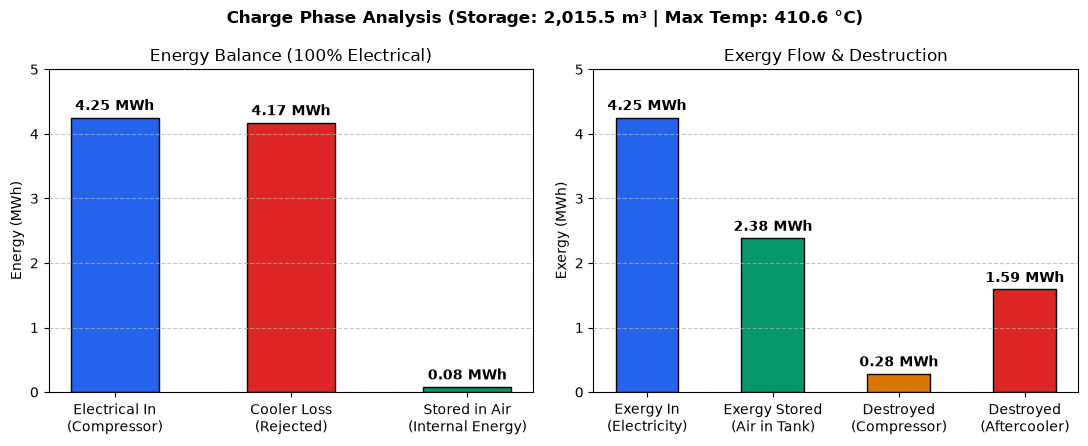

In [63]:
# ==============================================================================
# Charge Phase Energy Balance Plot
# ==============================================================================

# Visualizations: Charge Energy Balance & Exergy Destruction
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle(f"Charge Phase Analysis (Storage: {V_charged:,.1f} m³ | Max Temp: {t_max_comp_C:.1f} °C)", fontweight="bold")

# Energy Balance
en_labels = ["Electrical In\n(Compressor)", "Cooler Loss\n(Rejected)", "Stored in Air\n(Internal Energy)"]
en_vals = [w_comp_MWh, q_cooler_MWh, w_comp_MWh - q_cooler_MWh]
bars1 = ax1.bar(en_labels, en_vals, color=["#2563eb", "#dc2626", "#059669"], edgecolor="black", width=0.5)
ax1.set_ylabel("Energy (MWh)")
ax1.set_title("Energy Balance (100% Electrical)")
ax1.set_ylim(0, 5.0)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars1:
    ax1.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

# ==============================================================================
# Charge Phase Exergy Destruction Plot 
# ==============================================================================
ex_labels = ["Exergy In\n(Electricity)", "Exergy Stored\n(Air in Tank)", "Destroyed\n(Compressor)", "Destroyed\n(Aftercooler)"]
ex_vals = [w_comp_MWh, exergy_stored_MWh, exergy_destroyed_comp_MWh, exergy_destroyed_cooler_MWh]

bars2 = ax2.bar(ex_labels, ex_vals, color=["#2563eb", "#059669", "#d97706", "#dc2626"], edgecolor="black", width=0.5)
ax2.set_ylabel("Exergy (MWh)")
ax2.set_title("Exergy Flow & Destruction")
ax2.set_ylim(0, 5.0)
ax2.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars2:
    ax2.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()
plt.show()


## 5.2 Discharge Phase

In [ ]:
'''
# ==============================================================================
# Discharge Phase Energy Balance 
# ==============================================================================
fuel_heat_mean = df_discharge["Comb.Qdot_fuel"].mean()
turbine_energy_J = shaft_power_mean * t_discharge                   # [J]
fuel_energy_J = fuel_heat_mean * t_discharge                        # [J]
air_mass_kg = air_flow_mean_dis * t_discharge                       # [kg]
fuel_mass_kg = fuel_flow_mean_dis * t_discharge                     # [kg]

w_turb_MWh = turbine_energy_J / 3.6e9
q_fuel_MWh = fuel_energy_J / 3.6e9

# [Efficiency] Fuel electric equivalent energy (weighted at eta_fuel = 0.40)
# Equation: W_fuel_eq = Eta_Fuel * fuel_energy_J
fuel_electric_equivalent_J = Eta_Fuel * fuel_energy_J

# [Energy / Work] Total cycle weighted input energy
# Equation: W_in_weighted = W_comp_total + Eta_Fuel * fuel_energy_J
weighted_input_J = W_comp_total + fuel_electric_equivalent_J

# [Efficiency] Overall round-trip efficiency
# Equation: round_trip_efficiency = W_turb / (W_comp + eta_fuel * Q_fuel)
round_trip_efficiency = turbine_energy_J / weighted_input_J

elec_share = 100.0 * W_comp_total / weighted_input_J
fuel_share = 100.0 * fuel_electric_equivalent_J / weighted_input_J


# ==============================================================================
# Discharge Exergy Balance 
# ==============================================================================
# Specific flow exergies at component ports [J/kg]
ex_air_in = specific_flow_exergy(df_discharge["Comb.air_in.p"].mean(), df_discharge["Comb.air_in.h"].mean(), "Air")
ex_turb_in = specific_flow_exergy(df_discharge["turbine.inl.p"].mean(), df_discharge["turbine.inl.h"].mean(), "Air")
ex_exhaust = specific_flow_exergy(df_discharge["turbine.out.p"].mean(), df_discharge["turbine.out.h"].mean(), "Air")

# Flow exergy of air into combustor [J]
air_exergy_J = air_mass_kg * ex_air_in

# Fuel chemical exergy (1.04 x combustor fuel energy input) [J]
fuel_exergy_J = 1.04 * fuel_energy_J

# Total exergy input to discharge system [J]
exergy_input_J = air_exergy_J + fuel_exergy_J

# Exergy entering turbine [J]
turb_in_exergy_J = air_mass_kg * ex_turb_in

# Exhaust exergy lost to environment [J]
exhaust_exergy_J = air_mass_kg * ex_exhaust

# Delivered turbine shaft work exergy [J]
turbine_work_exergy_J = turbine_energy_J

# Combustor exergy destruction [J]
combustor_exergy_destruction_J = exergy_input_J - turb_in_exergy_J

# Turbine exergy destruction [J]
turbine_exergy_destruction_J = turb_in_exergy_J - exhaust_exergy_J - turbine_work_exergy_J

# Exergy balance residual [J]
exergy_balance_residual_J = (
    exergy_input_J - turbine_work_exergy_J - exhaust_exergy_J
    - combustor_exergy_destruction_J - turbine_exergy_destruction_J
)

# Convert exergies to MWh
exergy_input_MWh = exergy_input_J / 3.6e9
combustor_exergy_destruction_MWh = combustor_exergy_destruction_J / 3.6e9
turbine_exergy_destruction_MWh = turbine_exergy_destruction_J / 3.6e9
exhaust_exergy_MWh = exhaust_exergy_J / 3.6e9
turbine_work_exergy_MWh = turbine_work_exergy_J / 3.6e9
exergy_balance_residual_MWh = exergy_balance_residual_J / 3.6e9

# Losses
exhaust_loss_MWh = (air_mass_kg * (turbine.out.h - h_tank_discharge)) / 3.6e9
mech_loss_MWh = ((1.0 - Eta_Mech) / Eta_Mech * turbine_energy_J) / 3.6e9
t_max_tit_C = Ttit - 273.15
'''

In [60]:
# ==============================================================================
# Discharge Phase Energy Balance
# ==============================================================================
fuel_heat_mean = df_discharge["Comb.Qdot_fuel"].mean()
turbine_energy_J = shaft_power_mean * t_discharge                   # [J]
fuel_energy_J = fuel_heat_mean * t_discharge                        # [J]
air_mass_kg = air_flow_mean_dis * t_discharge                       # [kg]
fuel_mass_kg = fuel_flow_mean_dis * t_discharge                     # [kg]
gas_mass_kg = air_mass_kg + fuel_mass_kg                            # [kg] Total gas mass through turbine

w_turb_MWh = turbine_energy_J / 3.6e9
q_fuel_MWh = fuel_energy_J / 3.6e9

# [Efficiency] Fuel electric equivalent energy (weighted at eta_fuel = 0.40)
fuel_electric_equivalent_J = Eta_Fuel * fuel_energy_J

# [Energy / Work] Total cycle weighted input energy
weighted_input_J = W_comp_total + fuel_electric_equivalent_J

# [Efficiency] Overall round-trip efficiency
round_trip_efficiency = turbine_energy_J / weighted_input_J

elec_share = 100.0 * W_comp_total / weighted_input_J
fuel_share = 100.0 * fuel_electric_equivalent_J / weighted_input_J


# ==============================================================================
# Discharge Exergy Balance
# ==============================================================================
p_air_in_mean = df_discharge["Comb.air_in.p"].mean()
h_air_in_mean = df_discharge["Comb.air_in.h"].mean()
p_turb_in_mean = df_discharge["turbine.inl.p"].mean()
h_turb_in_mean = df_discharge["turbine.inl.h"].mean()
p_turb_out_mean = df_discharge["turbine.out.p"].mean()
h_turb_out_mean = df_discharge["turbine.out.h"].mean()

# Specific flow exergies at component ports [J/kg]
ex_air_in = specific_flow_exergy(p_air_in_mean, h_air_in_mean, "Air")
ex_turb_in = specific_flow_exergy(p_turb_in_mean, h_turb_in_mean, "Air")
ex_exhaust = specific_flow_exergy(p_turb_out_mean, h_turb_out_mean, "Air")

# Flow exergy of air into combustor [J]
air_exergy_J = air_mass_kg * ex_air_in

# Fuel chemical exergy (1.04 x combustor fuel energy input) [J]
fuel_exergy_J = 1.04 * fuel_energy_J

# Total exergy input to discharge system [J]
exergy_input_J = air_exergy_J + fuel_exergy_J

# Exergy entering turbine and leaving exhaust (uses total gas_mass_kg) [J]
turb_in_exergy_J = gas_mass_kg * ex_turb_in
exhaust_exergy_J = gas_mass_kg * ex_exhaust
turbine_work_exergy_J = turbine_energy_J

# Mechanical friction/generator loss [J]
mech_loss_J = ((1.0 - Eta_Mech) / Eta_Mech) * turbine_energy_J

# Combustor exergy destruction [J]
combustor_exergy_destruction_J = exergy_input_J - turb_in_exergy_J

# Turbine exergy destruction via entropy generation (Gouy-Stodola) + mechanical loss [J]
s_turb_in_mean = PropsSI("S", "P", p_turb_in_mean, "H", h_turb_in_mean, "Air")
s_turb_out_mean = PropsSI("S", "P", p_turb_out_mean, "H", h_turb_out_mean, "Air")
turbine_exergy_destruction_J = gas_mass_kg * T0 * (s_turb_out_mean - s_turb_in_mean) + mech_loss_J

# Independent Exergy balance residual [J]
exergy_balance_residual_J = (
    exergy_input_J - turbine_work_exergy_J - exhaust_exergy_J
    - combustor_exergy_destruction_J - turbine_exergy_destruction_J
)

# Convert exergies to MWh
exergy_input_MWh = exergy_input_J / 3.6e9
combustor_exergy_destruction_MWh = combustor_exergy_destruction_J / 3.6e9
turbine_exergy_destruction_MWh = turbine_exergy_destruction_J / 3.6e9
exhaust_exergy_MWh = exhaust_exergy_J / 3.6e9
turbine_work_exergy_MWh = turbine_work_exergy_J / 3.6e9
exergy_balance_residual_MWh = exergy_balance_residual_J / 3.6e9

# Thermal exhaust and mechanical losses [MWh]
h0_air = PropsSI("H", "T", T0, "P", P0, "Air")
exhaust_loss_MWh = (gas_mass_kg * (h_turb_out_mean - h0_air)) / 3.6e9
mech_loss_MWh = mech_loss_J / 3.6e9
t_max_tit_C = Ttit - 273.15

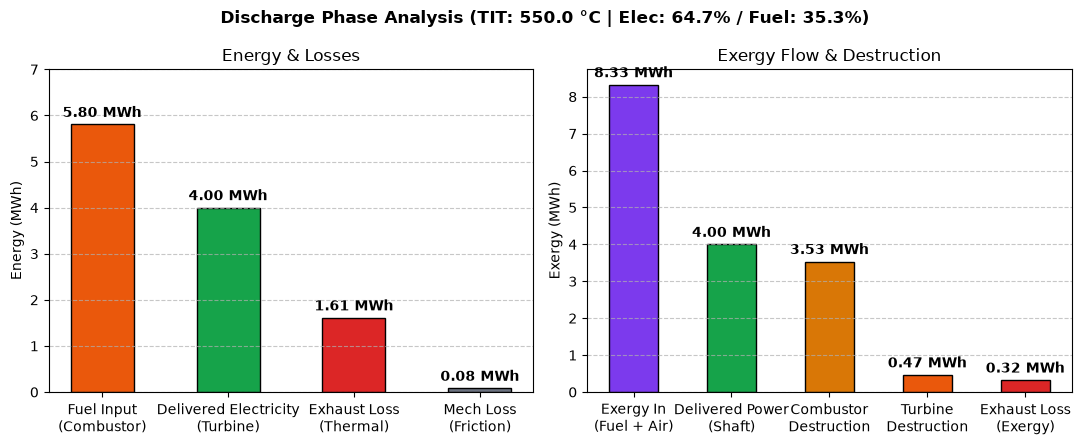

In [61]:
# Visualizations: Discharge Energy & Exergy Losses
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle(f"Discharge Phase Analysis (TIT: {t_max_tit_C:.1f} °C | Elec: {elec_share:.1f}% / Fuel: {fuel_share:.1f}%)", fontweight="bold")

# Energy Balance & Losses
dis_labels = ["Fuel Input\n(Combustor)", "Delivered Electricity\n(Turbine)", "Exhaust Loss\n(Thermal)", "Mech Loss\n(Friction)"]
dis_vals = [q_fuel_MWh, w_turb_MWh, exhaust_loss_MWh, mech_loss_MWh]
bars3 = ax1.bar(dis_labels, dis_vals, color=["#ea580c", "#16a34a", "#dc2626", "#6b7280"], edgecolor="black", width=0.5)
ax1.set_ylabel("Energy (MWh)")
ax1.set_title("Energy & Losses")
ax1.set_ylim(0, 7.0)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars3:
    ax1.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

# Exergy Destruction
ex_dis_labels = ["Exergy In\n(Fuel + Air)", "Delivered Power\n(Shaft)", "Combustor\nDestruction", "Turbine\nDestruction", "Exhaust Loss\n(Exergy)"]
ex_dis_vals = [exergy_input_MWh, turbine_work_exergy_J / 3.6e9, combustor_exergy_destruction_MWh, turbine_exergy_destruction_MWh, exhaust_exergy_MWh]
bars4 = ax2.bar(ex_dis_labels, ex_dis_vals, color=["#7c3aed", "#16a34a", "#d97706", "#ea580c", "#dc2626"], edgecolor="black", width=0.5)
ax2.set_ylabel("Exergy (MWh)")
ax2.set_title("Exergy Flow & Destruction")
ax2.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars4:
    ax2.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()
plt.show()

## 5.3 Charge & DisCharge Summary Tables

In [ ]:
charge_summary_data = [
    ("Charge duration", f"{t_charge / 3600:.1f}", "h"),
    ("Ambient inlet temperature", f"{T0 - 273.15:.1f}", "°C"),
    ("Ambient inlet pressure", f"{P0 / 1e5:.3f}", "bar"),
    ("Storage pressure", f"{Pmax / 1e5:.1f}", "bar"),
    ("Air mass flow rate", f"{Mdot_charge:.4f}", "kg/s"),
    ("Compressor isentropic efficiency", f"{Eta_ISC * 100:.1f}", "%"),
    ("Compressor outlet temperature", f"{Comp_Charge.out.T - 273.15:.1f}", "°C"),
    ("Mean compressor power", f"{wdot_comp_MW:.3f}", "MW"),
    ("Compressor energy used", f"{w_comp_MWh:.3f}", "MWh"),
    ("Cooler outlet air target", f"{T_cooler_out - 273.15:.1f}", "°C"),
    ("Cooling-water mass flow rate", f"{Mdot_water:.2f}", "kg/s"),
    ("Cooling-water inlet temperature", f"{T_water_in - 273.15:.1f}", "°C"),
    ("Cooling-water outlet temperature", f"{be_water.T(Hex_Charge.cold_out.p, Hex_Charge.cold_out.h) - 273.15:.1f}", "°C"),
    ("Air-side heat-transfer coefficient", f"{h_film_air:.1f}", "W/(m²·K)"),
    ("Water-side heat-transfer coefficient", f"{h_film_water:.1f}", "W/(m²·K)"),
    ("Cooler cold/hot area ratio", f"{Ratio_Area_cold_to_hot:.4f}", "-"),
    ("Cooler air-side area (A_air)", f"{A_air_cooler:.1f}", "m²"),
    ("Cooler conductance (UA)", f"{Hex_Charge.UA:.1f}", "W/K"),
    ("Cooler heat rejected", f"{q_cooler_MWh:.3f}", "MWh"),
    ("Air mass added to tank", f"{m_air_added_sim:.1f}", "kg"),
    ("Tank volume at start / end", f"{V_tank_initial_sim:.1f} / {V_charged:.1f}", "m³"),
    ("Final tank air temperature", f"{T_tank_final_sim - 273.15:.1f}", "°C"),
    ("Final tank pressure", f"{P_tank_final_sim / 1e5:.2f}", "bar"),
    ("Tank wall heat capacity", f"{Cwall / 1e6:.2f}", "MJ/K"),
    ("Tank wall conductance (UA)", f"{UA_wall:.1f}", "W/K"),
    ("Exergy stored in tank air", f"{exergy_stored_MWh:.3f}", "MWh"),
    ("Compressor exergy destruction", f"{exergy_destroyed_comp_MWh:.3f}", "MWh"),
    ("Aftercooler exergy destruction", f"{exergy_destroyed_cooler_MWh:.3f}", "MWh"),
]
df_charge_overview = pd.DataFrame(charge_summary_data, columns=["Charge-phase parameter", "Value", "Unit"])
print("CHARGE PHASE SUMMARY")
display(df_charge_overview)

discharge_summary_data = [
    ("Discharge duration", f"{t_discharge / 3600:.1f}", "h"),
    ("Storage pressure", f"{Pmax / 1e5:.1f}", "bar"),
    ("Initial tank air temperature", f"{T0 - 273.15:.1f}", "°C"),
    ("Turbine inlet temperature target", f"{Ttit - 273.15:.1f}", "°C"),
    ("Combustor pressure drop", f"{dp_comb_rel * 100:.1f}", "%"),
    ("Turbine isentropic efficiency", f"{Eta_IST * 100:.1f}", "%"),
    ("Mechanical / generator efficiency", f"{Eta_Mech * 100:.1f}", "%"),
    ("Target turbine power", f"{W_target / 1e6:.2f}", "MW"),
    ("Average simulated turbine power", f"{shaft_power_mean / 1e6:.3f}", "MW"),
    ("Turbine energy delivered", f"{w_turb_MWh:.3f}", "MWh"),
    ("Design air mass flow rate", f"{Mdot_discharge:.4f}", "kg/s"),
    ("Average simulated air flow rate", f"{air_flow_mean_dis:.4f}", "kg/s"),
    ("Average simulated fuel flow rate", f"{fuel_flow_mean_dis:.5f}", "kg/s"),
    ("Fuel heating value", f"{Comb.params['LHV'] / 1e6:.1f}", "MJ/kg"),
    ("Combustion heat supplied", f"{q_fuel_MWh:.3f}", "MWh"),
    ("Air mass discharged", f"{air_mass_kg:.1f}", "kg"),
    ("Fuel mass consumed", f"{fuel_mass_kg:.1f}", "kg"),
    ("Tank volume at start / end", f"{V_discharge_sized:.1f} / {V_discharge_final:.3f}", "m³"),
    ("Tank shell outer diameter", f"{Diameter_Tank_out:.2f}", "m"),
    ("Tank wall thickness", f"{Thickness_wall:.3f}", "m"),
    ("Tank wall heat capacity", f"{Cwall / 1e6:.2f}", "MJ/K"),
    ("Tank wall conductance (UA)", f"{UA_wall:.1f}", "W/K"),
    ("Exhaust energy", f"{exhaust_loss_MWh:.3f}", "MWh"),
    ("Mechanical loss", f"{mech_loss_MWh:.3f}", "MWh"),
    ("Overall round-trip efficiency", f"{round_trip_efficiency * 100:.2f}", "%"),
    ("Fuel electric-equivalent share", f"{fuel_share:.1f}", "%"),
    ("Exergy entering discharge cycle", f"{exergy_input_MWh:.3f}", "MWh"),
    ("Combustor exergy destruction", f"{combustor_exergy_destruction_MWh:.3f}", "MWh"),
    ("Turbine exergy destruction", f"{turbine_exergy_destruction_MWh:.3f}", "MWh"),
    ("Exhaust exergy", f"{exhaust_exergy_MWh:.3f}", "MWh"),
    ("Exergy balance residual", f"{exergy_balance_residual_MWh:.6f}", "MWh"),
]
df_discharge_overview = pd.DataFrame(discharge_summary_data, columns=["Discharge-phase parameter", "Value", "Unit"])
print("DISCHARGE PHASE SUMMARY")
display(df_discharge_overview)

CHARGE PHASE SUMMARY


,Charge-phase parameter,Value,Unit
0,Charge duration,4.0,h
1,Ambient inlet temperature,15.0,°C
2,Ambient inlet pressure,1.013,bar
3,Storage pressure,16.0,bar
4,Air mass flow rate,2.6122,kg/s
5,Compressor isentropic efficiency,85.0,%
6,Compressor outlet temperature,410.6,°C
7,Mean compressor power,1.061,MW
8,Compressor energy used,4.254,MWh
9,Cooler outlet air target,25.0,°C


DISCHARGE PHASE SUMMARY


,Discharge-phase parameter,Value,Unit
0,Discharge duration,4.0,h
1,Storage pressure,16.0,bar
2,Initial tank air temperature,15.0,°C
3,Turbine inlet temperature target,550.0,°C
4,Combustor pressure drop,4.0,%
5,Turbine isentropic efficiency,88.0,%
6,Mechanical / generator efficiency,98.0,%
7,Target turbine power,1.00,MW
8,Average simulated turbine power,1.000,MW
9,Turbine energy delivered,4.000,MWh


# 6. Parametric Study: Sensitivity to Storage Pressure (10 to 25 bar)
Sweeps the storage pressure $P_{\text{max}}$ from 10 bar to 25 bar to evaluate how pressure ratio affects the required storage volume, compressor electrical work, and overall round-trip efficiency using real simulated values.


In [ ]:
# ==============================================================================
# Parametric Study: Storage Pressure Sweep (10 to 25 bar)
# ==============================================================================

#Running the full simulation for multiple pressures takes from 15min to 20min
#To do so change "Full_sim" state to True
Full_sim = False

if Full_sim == True:
    pressure_list_bar = [10, 12, 14, 16, 18, 20, 22, 25]

    sweep_pressure_bar = []
    sweep_pressure_ratio = []
    sweep_efficiency_pct = []
    sweep_v_charged_m3 = []
    sweep_v_initial_m3 = []
    sweep_w_comp_mwh = []
    sweep_q_fuel_mwh = []
    sweep_w_turb_mwh = []
    sweep_air_mass_kg = []
    sweep_fuel_mass_kg = []
    sweep_t_comp_out_c = []
    sweep_q_cooler_mwh = []

    print(f"Beginning parametric simulation across storage pressures: {pressure_list_bar} bar...\n")

    for p_bar in pressure_list_bar:
        Pmax_i = p_bar * 1e5  # [Pa] Storage pressure
        print(f"--- Simulating Pmax = {p_bar:.1f} bar ---")

        # 1. Recalculate pressure-dependent thermodynamic states
        P_turb_in_i = Pmax_i * (1.0 - dp_comb_rel)
        h_turb_in_i = PropsSI("H", "T", Ttit, "P", P_turb_in_i, "Air")
        s_turb_in_i = PropsSI("S", "T", Ttit, "P", P_turb_in_i, "Air")
        h_turb_out_s_i = PropsSI("H", "P", P0, "S", s_turb_in_i, "Air")
        w_sp_i = Eta_Mech * Eta_IST * (h_turb_in_i - h_turb_out_s_i)
        Mdot_discharge_i = W_target / w_sp_i
        Mass_discharge_total_i = Mdot_discharge_i * t_discharge
        h_tank_discharge_i = PropsSI("H", "T", T0, "P", Pmax_i, "Air")
        rho_tank_discharge_i = PropsSI("D", "T", T0, "P", Pmax_i, "Air")

        # 2. Recalculate vessel geometry and conductance for current Pmax
        V_tank_initial_i = Mass_discharge_total_i / rho_tank_discharge_i
        Length_Tank_i = V_tank_initial_i / Area_Tank_in_cs
        Area_Tank_in_surf_i = 2.0 * np.pi * r_in * Length_Tank_i
        Volume_Tank_Shell_i = Area_Tank_Shell_cs * Length_Tank_i
        Mass_Tank_i = Density_Steel_304 * Volume_Tank_Shell_i
        Cwall_i = Mass_Tank_i * Cp_Tank
        R_conv_in_i = 1.0 / (h_in * Area_Tank_in_surf_i)
        R_wall_inner_i = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank_i)
        UA_wall_i = 1.0 / (R_conv_in_i + R_wall_inner_i)

        # 3. Iterate Discharge Cycle
        target_vol = 0.0
        V_guess_i = V_tank_initial_i
        err_i = float("inf")
        while abs(err_i) >= 0.1:
            Source_i = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
            Comb_i = CombustionChamber(name="Comb", backend_air=be_air, backend_fuel=be_fuel, LHV=50e6, eta_comb=1.0, dp_rel=dp_comb_rel)
            Fuel_in_i = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
            turbine_i = Turbine(name="turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
            Tank_i = TankConstP(name="Tank", backend=be_air, p=Pmax_i, h_init=h_tank_discharge_i, V_init=V_guess_i, C_wall=Cwall_i, T_wall_init=T0, UA_wall=UA_wall_i, Q_heater=0.0)
            Exhaust_i = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

            sys_dis_i = System("Discharge_Cycle_i")
            sys_dis_i.add(Source_i, Tank_i, turbine_i, Comb_i, Fuel_in_i, Exhaust_i)
            sys_dis_i.connect(Source_i.port,  Tank_i.inl)
            sys_dis_i.connect(Tank_i.out,     Comb_i.air_in)
            sys_dis_i.connect(Fuel_in_i.port, Comb_i.fuel_in)
            sys_dis_i.connect(Comb_i.gas_out, turbine_i.inl)
            sys_dis_i.connect(turbine_i.out,  Exhaust_i.port)
            sys_dis_i.add_constraint(lambda: be_air.T(Comb_i.gas_out.p, Comb_i.gas_out.h) - Ttit, "TIT_550C")
            sys_dis_i.add_constraint(lambda: Eta_Mech * turbine_i.inl.mdot * (turbine_i.inl.h - turbine_i.out.h) - W_target, "Wdot_1MW")
            sys_dis_i.set_start_port(Tank_i.out,      p=Pmax_i,           T=Tank_i.out.T,    mdot= -Mdot_discharge_i)
            sys_dis_i.set_start_port(Fuel_in_i.port,  p=P0,               T=T0,              mdot= -Mdot_fuel_guess)
            sys_dis_i.set_start_port(Comb_i.air_in,   p=Tank_i.out.p,     T=Tank_i.out.T,    mdot=  Mdot_discharge_i)
            sys_dis_i.set_start_port(Comb_i.gas_out,  p=Comb_i.gas_out.p, T=Ttit,            mdot= -Mdot_discharge_i)
            sys_dis_i.set_start_port(turbine_i.inl,   p=Comb_i.gas_out.p, T=Ttit,            mdot=  Mdot_discharge_i)
            sys_dis_i.set_start_port(turbine_i.out,   p=P0,               T=turbine_i.out.T, mdot= -Mdot_discharge_i)
            sys_dis_i.set_start_port(Exhaust_i.port,  p=P0,               T=turbine_i.out.T, mdot=  Mdot_discharge_i)
            sys_dis_i.init_starts()

            results_dis_i = simulate(sys_dis_i, t_end=t_discharge, dt=240, init="consistent", progress=False)
            df_dis_i = results_dis_i.to_dataframe()
            err_i = df_dis_i["Tank.V"].iloc[-1] - target_vol
            if abs(err_i) < 0.1:
                break
            V_guess_i -= err_i

        # 4. Charge Flow Rate & Enthalpy
        V_start_i = df_dis_i["Tank.V"].iloc[0]
        Density_dis_i = PropsSI("D", "T", Tank_i.out.T, "P", Tank_i.out.p, "Air")
        Mass_real_i = V_start_i * Density_dis_i
        Mdot_charge_i = Mass_real_i / t_charge
        h_tank_charge_i = PropsSI("H", "T", T_cooler_out, "P", Pmax_i, "Air")

        # 5. Simulate Charge
        Source_ch_i = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge_i, backend=be_air)
        Comp_ch_i = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)
        Water_Cold_i = FluidBoundary(name="Water_Cold", p=P_water_in, T=T_water_in, mdot=-Mdot_water, backend=be_water)
        Water_Hot_i = FluidBoundary(name="Water_Hot", backend=be_water)
        Hex_ch_i = SizingHX(name="Hex_Charge", backend_hot=be_air, backend_cold=be_water, 
                            h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
        Tank_ch_i = TankConstP(name="Tank_Charge", backend=be_air, p=Pmax_i, h_init=h_tank_charge_i, 
                            V_init=0.0, C_wall=Cwall_i, T_wall_init=T0, UA_wall=UA_wall_i, Q_heater=0.0)
        Closed_Outlet_i = FluidBoundary(name="Closed_Outlet_Charge", p=None, T=None, h=None, mdot=0.0, backend=be_air)

        sys_ch_i = System("Charge_Cycle_i")
        sys_ch_i.add(Source_ch_i, Comp_ch_i, Hex_ch_i, Water_Cold_i, Water_Hot_i, Tank_ch_i, Closed_Outlet_i)
        sys_ch_i.connect(Source_ch_i.port,     Comp_ch_i.inl)
        sys_ch_i.connect(Comp_ch_i.out,        Hex_ch_i.hot_in)
        sys_ch_i.connect(Water_Cold_i.port,    Hex_ch_i.cold_in)
        sys_ch_i.connect(Hex_ch_i.cold_out,    Water_Hot_i.port)
        sys_ch_i.connect(Hex_ch_i.hot_out,     Tank_ch_i.inl)
        sys_ch_i.connect(Tank_ch_i.out,        Closed_Outlet_i.port)
        sys_ch_i.add_constraint(lambda: be_air.T(Hex_ch_i.hot_out.p, Hex_ch_i.hot_out.h) - T_cooler_out, name="cooler_outlet_temperature")

        sys_ch_i.set_start_port(Comp_ch_i.inl,    p=P0,          T=T0,          mdot= Mdot_charge_i)
        sys_ch_i.set_start_port(Comp_ch_i.out,    p=Pmax_i,      T=300 + 273,   mdot=-Mdot_charge_i)
        sys_ch_i.set_start_port(Hex_ch_i.hot_in,  p=Pmax_i,      T=300 + 273,   mdot= Mdot_charge_i)
        sys_ch_i.set_start_port(Hex_ch_i.hot_out, p=Pmax_i,      T=T_cooler_out, mdot=-Mdot_charge_i)
        sys_ch_i.set_start_port(Tank_ch_i.inl,    p=Pmax_i,      T=T_cooler_out, mdot= Mdot_charge_i)
        sys_ch_i.set_start_port(Tank_ch_i.out,    p=Pmax_i,      T=T_cooler_out, mdot= 0.0)
        sys_ch_i.set_start_port(Hex_ch_i.cold_in,  p=P_water_in,  T=T_water_in,  mdot= Mdot_water)
        sys_ch_i.set_start_port(Hex_ch_i.cold_out, p=P_water_in,  T=100 + 273,   mdot=-Mdot_water)
        sys_ch_i.init_starts()

        results_ch_i = simulate(sys_ch_i, t_end=t_charge, dt=240, init="consistent", progress=False)
        df_ch_i = results_ch_i.to_dataframe()

        # 6. Real Simulated Outputs
        Wdot_comp_i = -df_ch_i["Comp_Charge.Wdot"].to_numpy()
        W_comp_J_i = Wdot_comp_i.mean() * t_charge
        V_charged_i = df_ch_i["Tank_Charge.V"].iloc[-1]
        t_comp_out_C_i = Comp_ch_i.out.T - 273.15
        q_cooler_J_i = Mdot_charge_i * (Comp_ch_i.out.h - Hex_ch_i.hot_out.h) * t_charge

        W_turb_J_i = df_dis_i["turbine.Wdot"].mean() * t_discharge
        Q_fuel_J_i = df_dis_i["Comb.Qdot_fuel"].mean() * t_discharge
        air_mass_i = df_dis_i["Tank.fluid.out.mdot"].abs().mean() * t_discharge
        fuel_mass_i = df_dis_i["Fuel_in.port.mdot"].abs().mean() * t_discharge

        # Round-trip efficiency using simulated values
        W_fuel_eq_i = Eta_Fuel * Q_fuel_J_i
        W_in_weighted_i = W_comp_J_i + W_fuel_eq_i
        eta_rt_i = W_turb_J_i / W_in_weighted_i

        # Store
        sweep_pressure_bar.append(p_bar)
        sweep_pressure_ratio.append(Pmax_i / P0)
        sweep_efficiency_pct.append(100.0 * eta_rt_i)
        sweep_v_charged_m3.append(V_charged_i)
        sweep_v_initial_m3.append(V_tank_initial_i)
        sweep_w_comp_mwh.append(W_comp_J_i / 3.6e9)
        sweep_q_fuel_mwh.append(Q_fuel_J_i / 3.6e9)
        sweep_w_turb_mwh.append(W_turb_J_i / 3.6e9)
        sweep_air_mass_kg.append(air_mass_i)
        sweep_fuel_mass_kg.append(fuel_mass_i)
        sweep_t_comp_out_c.append(t_comp_out_C_i)
        sweep_q_cooler_mwh.append(q_cooler_J_i / 3.6e9)

        print(f"  -> Eff: {100.0 * eta_rt_i:.2f}% | Charged Vol: {V_charged_i:.1f} m³ | W_comp: {W_comp_J_i/3.6e9:.3f} MWh | Comp T_out: {t_comp_out_C_i:.1f} °C")

    # Summary Table
    df_sweep_results = pd.DataFrame({
        "Pressure (bar)": sweep_pressure_bar,
        "Pressure Ratio (P/P0)": [round(pr, 2) for pr in sweep_pressure_ratio],
        "Storage Volume (m³)": [round(v, 1) for v in sweep_v_charged_m3],
        "Air Mass (kg)": [round(m, 0) for m in sweep_air_mass_kg],
        "Fuel Mass (kg)": [round(f, 1) for f in sweep_fuel_mass_kg],
        "Compressor Energy (MWh)": [round(wc, 3) for wc in sweep_w_comp_mwh],
        "Fuel Energy (MWh)": [round(qf, 3) for qf in sweep_q_fuel_mwh],
        "Turbine Energy (MWh)": [round(wt, 3) for wt in sweep_w_turb_mwh],
        "Comp Outlet Temp (°C)": [round(tc, 1) for tc in sweep_t_comp_out_c],
        "Cooler Heat Loss (MWh)": [round(qc, 3) for qc in sweep_q_cooler_mwh],
        "Round-Trip Efficiency (%)": [round(eff, 2) for eff in sweep_efficiency_pct],
    })

    print("\n=== Parametric Pressure Sweep Summary Table (10 to 25 bar) ===")
    display(df_sweep_results)

    # 4-Panel Visualization
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("CAES Parametric Study: Performance vs. Storage Pressure & Pressure Ratio", fontsize=15, fontweight="bold")

    # Plot 1: Efficiency
    ax1 = axes[0, 0]
    ax1.plot(sweep_pressure_bar, sweep_efficiency_pct, marker="o", color="#2563eb", linewidth=2.2, label="Round-Trip Efficiency (%)")
    ax1.axvline(16.0, color="#dc2626", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
    ax1.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
    ax1.set_ylabel("Round-Trip Efficiency (%)", fontsize=11)
    ax1.set_title("1. Round-Trip Efficiency vs. Storage Pressure", fontsize=12, fontweight="bold")
    ax1.grid(True, linestyle="--", alpha=0.7)
    ax1.legend(loc="best")
    ax1_top = ax1.secondary_xaxis("top", functions=(lambda p: np.array(p)*1e5/P0, lambda pr: np.array(pr)*P0/1e5))
    ax1_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", fontsize=10)

    # Plot 2: Storage Volume
    ax2 = axes[0, 1]
    ax2.plot(sweep_pressure_bar, sweep_v_charged_m3, marker="s", color="#059669", linewidth=2.2, label="Dynamic Charged Volume ($m^3$)")
    ax2.plot(sweep_pressure_bar, sweep_v_initial_m3, marker="^", color="#10b981", linestyle=":", label="Initial Volume Estimate ($m^3$)")
    ax2.axvline(16.0, color="#dc2626", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
    ax2.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
    ax2.set_ylabel("Storage Volume ($m^3$)", fontsize=11)
    ax2.set_title("2. Storage Reservoir Volume vs. Storage Pressure", fontsize=12, fontweight="bold")
    ax2.grid(True, linestyle="--", alpha=0.7)
    ax2.legend(loc="best")
    ax2_top = ax2.secondary_xaxis("top", functions=(lambda p: np.array(p)*1e5/P0, lambda pr: np.array(pr)*P0/1e5))
    ax2_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", fontsize=10)

    # Plot 3: Energy Breakdown
    ax3 = axes[1, 0]
    ax3.plot(sweep_pressure_bar, sweep_w_comp_mwh, marker="o", color="#2563eb", linewidth=2.0, label="Compressor Electricity $W_{comp}$ (MWh)")
    ax3.plot(sweep_pressure_bar, sweep_q_fuel_mwh, marker="^", color="#ea580c", linewidth=2.0, label="Combustion Heat $Q_{fuel}$ (MWh)")
    ax3.plot(sweep_pressure_bar, sweep_w_turb_mwh, marker="d", color="#16a34a", linestyle="-.", linewidth=2.0, label="Delivered Electricity $W_{turb}$ (MWh)")
    ax3.axvline(16.0, color="#dc2626", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
    ax3.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
    ax3.set_ylabel("Energy (MWh per 4 h cycle)", fontsize=11)
    ax3.set_title("3. Cycle Energy Inputs & Delivery vs. Storage Pressure", fontsize=12, fontweight="bold")
    ax3.grid(True, linestyle="--", alpha=0.7)
    ax3.legend(loc="best")
    ax3_top = ax3.secondary_xaxis("top", functions=(lambda p: np.array(p)*1e5/P0, lambda pr: np.array(pr)*P0/1e5))
    ax3_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", fontsize=10)

    # Plot 4: Compressor Outlet Temp & Cooler Heat Rejection
    ax4 = axes[1, 1]
    color_temp = "#dc2626"
    color_heat = "#d97706"
    line1 = ax4.plot(sweep_pressure_bar, sweep_t_comp_out_c, marker="o", color=color_temp, linewidth=2.0, label="Comp. Outlet Temp (°C)")
    ax4.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
    ax4.set_ylabel("Compressor Discharge Temperature (°C)", color=color_temp, fontsize=11)
    ax4.tick_params(axis="y", labelcolor=color_temp)
    ax4.axvline(16.0, color="#6b7280", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
    ax4.grid(True, linestyle="--", alpha=0.7)

    ax4_right = ax4.twinx()
    line2 = ax4_right.plot(sweep_pressure_bar, sweep_q_cooler_mwh, marker="s", color=color_heat, linewidth=2.0, linestyle="--", label="Cooler Heat Loss (MWh)")
    ax4_right.set_ylabel("Cooler Heat Rejected (MWh)", color=color_heat, fontsize=11)
    ax4_right.tick_params(axis="y", labelcolor=color_heat)

    lines_combined = line1 + line2
    labels_combined = [l.get_label() for l in lines_combined]
    ax4.legend(lines_combined, labels_combined, loc="best")
    ax4.set_title("4. Compressor Thermal Stress & Cooler Loss vs. Pressure", fontsize=12, fontweight="bold")

    fig.tight_layout()
    plt.show()


